# Surface σ2 on a globe — MESACLIP piControl
Daily surface σ2 from the 0.1° POP run (`B.E.13.B1850C5.ne120_t12`, years 0500–0505),
rendered on a 3D globe viewed from below the South Pole with GeoVista.

In [1]:
import glob
import multiprocessing
import os
import shutil
from pathlib import Path
import subprocess
import warnings

import cloudpickle
import cmocean
import geovista as gv
from geovista.common import to_cartesian
import matplotlib
import matplotlib.pyplot as plt
import gsw
import numpy as np
import pyvista as pv
import vtk
import xarray as xr
from IPython.display import Image

import frame_worker   # worker side of the movie (frame_worker.py, next to this notebook)
from matplotlib.colors import ListedColormap
from tqdm.auto import tqdm

# Harmless noise: gsw NaNs on land, glow spheres without a CRS, no X server
warnings.filterwarnings("ignore", message="invalid value encountered")
warnings.filterwarnings("ignore", message="geovista found no coordinate")
os.environ["PYTHONWARNINGS"] = "ignore::RuntimeWarning"   # also silences movie workers
_ = pv.vtk_verbosity("off")

## Settings

In [2]:
# Input files
# File names past 0410 don't match their time stamps; these two hold 0493-02 to 0506-01
DATA_GLOB  = str(Path.home() / "MESACLIP_piControl_500year" /
                 "B.E.13.B1850C5.ne120_t12.sehires38.003.sunway_02.pop.h.nday1.{var}.05[01]*.nc")
YEARS      = ("0500", "0505")   # time range kept (by time stamp)
TOPO_PATH = "/glade/campaign/cesm/cesmdata/inputdata/atm/cam/topo/USGS-gtopo30_10min_c050419.nc"

# Look
WINDOW_SIZE       = (1920, 1080)   # image size in pixels (16:9, full HD)
SIGMA2_RANGE      = (34.8, 37.4)   # colour range for σ2 (kg/m³)
LAND_EXAGGERATION = 40             # vertical exaggeration of land/ice height
BACKGROUND        = ("#1c2b42", "#4a6890")   # (bottom, top) colours of the background gradient
HEADLIGHT_INTENSITY = 0.4          # extra light from the camera position
# VTK's built-in fonts have no Greek letters, so use matplotlib's DejaVu Sans for all text with σ
FONT      = os.path.join(matplotlib.get_data_path(), "fonts/ttf/DejaVuSans.ttf")
FONT_BOLD = os.path.join(matplotlib.get_data_path(), "fonts/ttf/DejaVuSans-Bold.ttf")

# Camera
VISIBLE_EDGE_LAT = -14   # latitude at the globe's visible edge (°N)

# Region: ocean and land data are cut here, a little north of the visible edge
NORTH_LIMIT_LAT = VISIBLE_EDGE_LAT + 5   # °N

# Regions outlined on the region map
#   box:   (lon west, lon east, lat south, lat north)
#   label: (lon, lat, alignment); alignment = which way the text runs from that point
REGIONS = {
    "Weddell Sea":  dict(box=(-62, -20, -78, -64),     label=(-17, -62.5, "left")),
    "Ross Sea":     dict(box=(160, 210, -78, -70),     label=(185, -67.5, "center")),
    "Prydz Bay":    dict(box=(70, 80, -69.5, -65.5),   label=(75, -64, "left")),
    "Adélie Coast": dict(box=(136, 145, -67.5, -64.5), label=(147, -63, "left")),
}
REGION_COLOR = "#ffd166"

## Surface σ2

In [3]:
# Grid (static) read once; the daily files then only need the data variable
first_sst_file = xr.open_dataset(sorted(glob.glob(DATA_GLOB.format(var="SST")))[0], decode_timedelta=True)
grid_vars = [name for name in first_sst_file.variables
             if name not in first_sst_file.dims and "time" not in first_sst_file[name].dims]

# Rows south of NORTH_LIMIT_LAT (row 0 is southernmost; TLAT = -1 marks POP's removed land blocks)
row_max_lat = first_sst_file.TLAT.where(first_sst_file.TLAT != -1).max("nlon")
south_rows = slice(0, int((row_max_lat < NORTH_LIMIT_LAT).sum()))
grid = first_sst_file[["TLONG", "TLAT", "HT"]].isel(nlat=south_rows).load()


def open_pop_daily(var):
    """Lazily open one POP daily variable: rows south of NORTH_LIMIT_LAT, YEARS only."""
    ds = xr.open_mfdataset(DATA_GLOB.format(var=var), engine="h5netcdf", decode_timedelta=True,
                           drop_variables=grid_vars + ["time_bound"],
                           chunks={"time": 1, "nlat": 800, "nlon": 1200},   # matches on-disk chunks
                           combine="nested", concat_dim="time",
                           data_vars="minimal", coords="minimal", compat="override")
    return ds[var].isel(nlat=south_rows).sel(time=slice(*YEARS))

sst = open_pop_daily("SST")
sss = open_pop_daily("SSS")

# POP gives practical salinity and potential temperature; gsw wants absolute salinity and conservative temperature
absolute_salinity = gsw.SA_from_SP(sss, 0, grid.TLONG, grid.TLAT)
conservative_temp = gsw.CT_from_pt(absolute_salinity, sst)
sigma2 = gsw.sigma2(absolute_salinity, conservative_temp)
sigma2 = sigma2.where(grid.HT > 0)                         # ocean only
sigma2 = sigma2.rename("sigma2").assign_coords(TLONG=grid.TLONG, TLAT=grid.TLAT)
sigma2.attrs.update(long_name="Surface sigma2", units="kg/m3")
sigma2

<xarray.DataArray 'sigma2' (time: 2190, nlat: 1092, nlon: 3600)> Size: 69GB
dask.array<where, shape=(2190, 1092, 3600), dtype=float64, chunksize=(1, 800, 1200), chunktype=numpy.ndarray>
Coordinates:
  * time     (time) object 18kB 0500-01-01 00:00:00 ... 0505-12-31 00:00:00
    TLONG    (nlat, nlon) float64 31MB -1.0 -1.0 -1.0 -1.0 ... 249.8 249.8 249.9
    TLAT     (nlat, nlon) float64 31MB -1.0 -1.0 -1.0 ... -9.013 -9.013 -9.013
    ULONG    (nlat, nlon) float64 31MB -1.0 -1.0 -1.0 ... -110.2 -110.1 -110.0
    ULAT     (nlat, nlon) float64 31MB -1.0 -1.0 -1.0 ... -8.964 -8.964 -8.964
Dimensions without coordinates: nlat, nlon
Attributes:
    long_name:     Surface sigma2
    units:         kg/m3
    grid_loc:      2110
    cell_methods:  time: mean

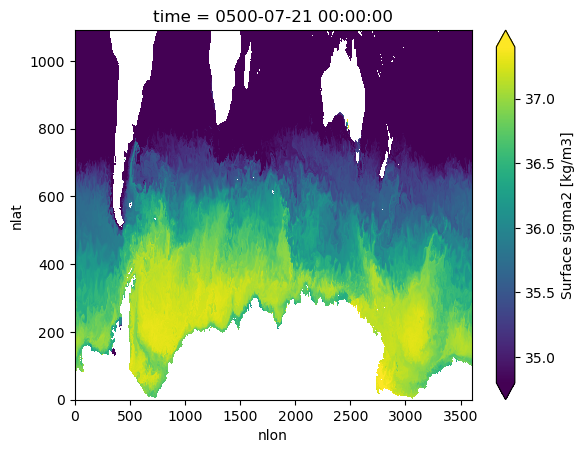

In [4]:
sigma2.sel(time="0500-07-21").squeeze("time").plot(vmin=SIGMA2_RANGE[0], vmax=SIGMA2_RANGE[1]);

## Globe scene
`build_static_globe` builds the static parts (background, lights, land, glow, camera); `add_sigma2_layer` draws
one day of σ2 and its date label, replacing the previous day via fixed mesh `name`s.

In [5]:
def wrap_longitude_seam(array):
    """Repeat the first column so the grid wraps the full 360° (avoids a gap on the globe)."""
    return np.c_[array, array[:, :1]]


def build_land_mesh():
    """GTOPO30 10' land (ice surface over Antarctica) south of NORTH_LIMIT_LAT, radially exaggerated."""
    topo = xr.open_dataset(TOPO_PATH).sel(lat=slice(-90, NORTH_LIMIT_LAT))
    height = topo.htopo.clip(min=0).where(topo.landfract > 0.5, -1)   # metres on land, -1 over ocean

    lon, lat = np.meshgrid(topo.lon, topo.lat)
    mesh = gv.Transform.from_2d(wrap_longitude_seam(lon), wrap_longitude_seam(lat),
                                data=wrap_longitude_seam(height.values), name="height")
    # Keep cells with any land corner; their ocean corners (-1) shade as sea level, giving a clean coastline
    land = mesh.threshold(0, scalars="height")

    earth_radius = 6.371e6  # m
    land.points *= (1 + LAND_EXAGGERATION * land["height"] / earth_radius)[:, None]
    return land


def build_static_globe(land):
    """Everything that is the same in every frame."""
    plotter = gv.GeoPlotter(off_screen=True, window_size=WINDOW_SIZE)
    globe_radius = 1   # GeoVista draws the globe with radius 1; glow and camera are set relative to it

    # All screen positions (text and colour bars) are fractions of the window, (0, 0) = bottom-left
    bottom, top = BACKGROUND
    plotter.set_background(bottom, top=top)
    plotter.add_light(pv.Light(light_type="headlight", intensity=HEADLIGHT_INTENSITY))

    land_cmap = ListedColormap(plt.cm.gray(np.linspace(0.25, 1, 256)))   # upper 75% of gray: sea level = mid-grey
    plotter.add_mesh(land, cmap=land_cmap, clim=(0, 4500), smooth_shading=True,
                     scalar_bar_args=dict(title="Land/ice height (m)\n", color="white", vertical=False,
                                          position_x=0.04, position_y=0.06, width=0.22, height=0.07,
                                          title_font_size=20, label_font_size=16, n_labels=4, fmt="%.0f"))
    plotter.add_text("Source: USGS GTOPO30 (10 arc-min)", position=(0.04, 0.02), viewport=True, color="white", font_size=11)
    plotter.add_base_layer(color="#3a3a36")   # fills gaps, e.g. under ice shelves

    # Atmosphere glow: faint halo of nested translucent shells just outside the globe, far side only
    n_shells           = 10
    first_shell_radius = 1.004 * globe_radius
    shell_spacing      = 0.0045 * globe_radius
    max_opacity        = 0.045   # innermost shell
    fade_exponent      = 1.5     # opacity falls off as (1 - shell_index / n_shells) ** fade_exponent
    for shell_index in range(n_shells):
        shell = pv.Sphere(radius=first_shell_radius + shell_index * shell_spacing,
                          theta_resolution=240, phi_resolution=120)
        opacity = max_opacity * (1 - shell_index / n_shells) ** fade_exponent
        plotter.add_mesh(shell, color="#6fa6e0", opacity=opacity,
                         culling="front", ambient=1, diffuse=0)

    plotter.add_text("Surface potential density\n(σ₂)", position=(0.03, 0.90), viewport=True, color="white", font_size=20,
                     font_file=FONT_BOLD)

    # Camera, set in lon/lat and converted to the x, y, z GeoVista uses (Earth's centre = (0, 0, 0), radius 1).
    # From distance d the horizon sits arccos(1/d) from the pole, so pick d to put it at VISIBLE_EDGE_LAT
    camera_distance = globe_radius / np.cos(np.deg2rad(VISIBLE_EDGE_LAT + 90))
    top_of_frame_lon = 0   # longitude at the top of the image (-60 puts the Peninsula up)

    camera_location = to_cartesian([0], [-90], radius=camera_distance)[0]   # directly below the South Pole
    look_at_point   = (0, 0, 0)                                             # Earth's centre
    up_direction    = to_cartesian([top_of_frame_lon], [0], radius=1)[0]    # towards top_of_frame_lon
    plotter.camera_position = [camera_location, look_at_point, up_direction]

    # VTK places the land colour-bar labels differently in the first screenshot than in later ones;
    # a throwaway first screenshot keeps them from jumping between movie frames
    plotter.screenshot(return_img=True)
    return plotter


def add_sigma2_layer(plotter, sigma2_day):
    """Draw one day of sigma2 (2D DataArray with TLONG/TLAT coords) plus its date label."""
    bar_title = "σ₂ (kg/m³)\n"
    mesh = gv.Transform.from_2d(wrap_longitude_seam(sigma2_day.TLONG.values),
                                wrap_longitude_seam(sigma2_day.TLAT.values),
                                data=wrap_longitude_seam(sigma2_day.values), name="sigma2")
    # threshold() drops NaN cells, incl. POP land blocks where TLAT/TLONG = -1
    plotter.add_mesh(mesh.threshold(), name="ocean", cmap=cmocean.cm.dense, clim=SIGMA2_RANGE,
                     scalar_bar_args=dict(title=bar_title, color="white", vertical=True,
                                          position_x=0.84, position_y=0.2, width=0.04, height=0.6,
                                          title_font_size=26, label_font_size=16, n_labels=5, fmt="%.1f"))

    # add_scalar_bar has no font_file option, so set FONT on the title directly
    title = plotter.scalar_bars[bar_title].GetTitleTextProperty()
    title.SetFontFamily(vtk.VTK_FONT_FILE)
    title.SetFontFile(FONT)

    date = sigma2_day.time.item()   # cftime
    label = f"{date.strftime('%B %d')}\nModel year: {date.year:04d}\nSource: MESACLIP"
    plotter.add_text(label, name="date", position=(0.03, 0.80), viewport=True, color="white", font_size=16)


def add_regions(plotter, regions):
    """Outline each region's lon/lat box and label it. Boxes go in a second layer so land never hides them."""
    overlay = vtk.vtkRenderer()
    overlay.SetLayer(1)
    overlay.SetActiveCamera(plotter.renderer.GetActiveCamera())
    plotter.ren_win.SetNumberOfLayers(2)
    plotter.ren_win.AddRenderer(overlay)

    for name, region in regions.items():
        lon_w, lon_e, lat_s, lat_n = region["box"]
        n = 100   # points per box side
        lons = np.concatenate([np.linspace(lon_w, lon_e, n), np.full(n, lon_e), np.linspace(lon_e, lon_w, n), np.full(n, lon_w)])
        lats = np.concatenate([np.full(n, lat_s), np.linspace(lat_s, lat_n, n), np.full(n, lat_n), np.linspace(lat_n, lat_s, n)])
        outline = pv.lines_from_points(to_cartesian(lons, lats, radius=1.004), close=True)
        box = pv.Actor(mapper=pv.DataSetMapper(outline))
        box.prop.color = REGION_COLOR
        box.prop.line_width = 3
        overlay.AddActor(box)

        # Label: pixel position of its lon/lat, shifted by the measured text size for the alignment
        label_lon, label_lat, alignment = region["label"]
        plotter.renderer.SetWorldPoint(*to_cartesian([label_lon], [label_lat], radius=1)[0], 1)
        plotter.renderer.WorldToDisplay()
        x, y, _ = plotter.renderer.GetDisplayPoint()
        label = plotter.add_text(name, position=(0, 0), color=REGION_COLOR, font_size=13,
                                 font_file=FONT_BOLD, shadow=True)
        bbox = [0.0] * 4
        label.GetBoundingBox(plotter.renderer, bbox)
        width, height = bbox[1] - bbox[0], bbox[3] - bbox[2]
        left = {"left": x, "center": x - width / 2, "right": x - width}[alignment]
        label.SetPosition(left, y - height / 2)
    plotter.render()   # apply the last label move before any screenshot

In [6]:
LAND_MESH = build_land_mesh()   # slow; built once and reused for every frame
LAND_MESH

UnstructuredGrid (0x152ba1800be0)
  N Cells:    302766
  N Points:   309559
  X Bounds:   -9.689e-01, 9.625e-01
  Y Bounds:   -9.941e-01, 8.805e-01
  Z Bounds:   -1.019e+00, -1.579e-01
  N Arrays:   4

## Single frame

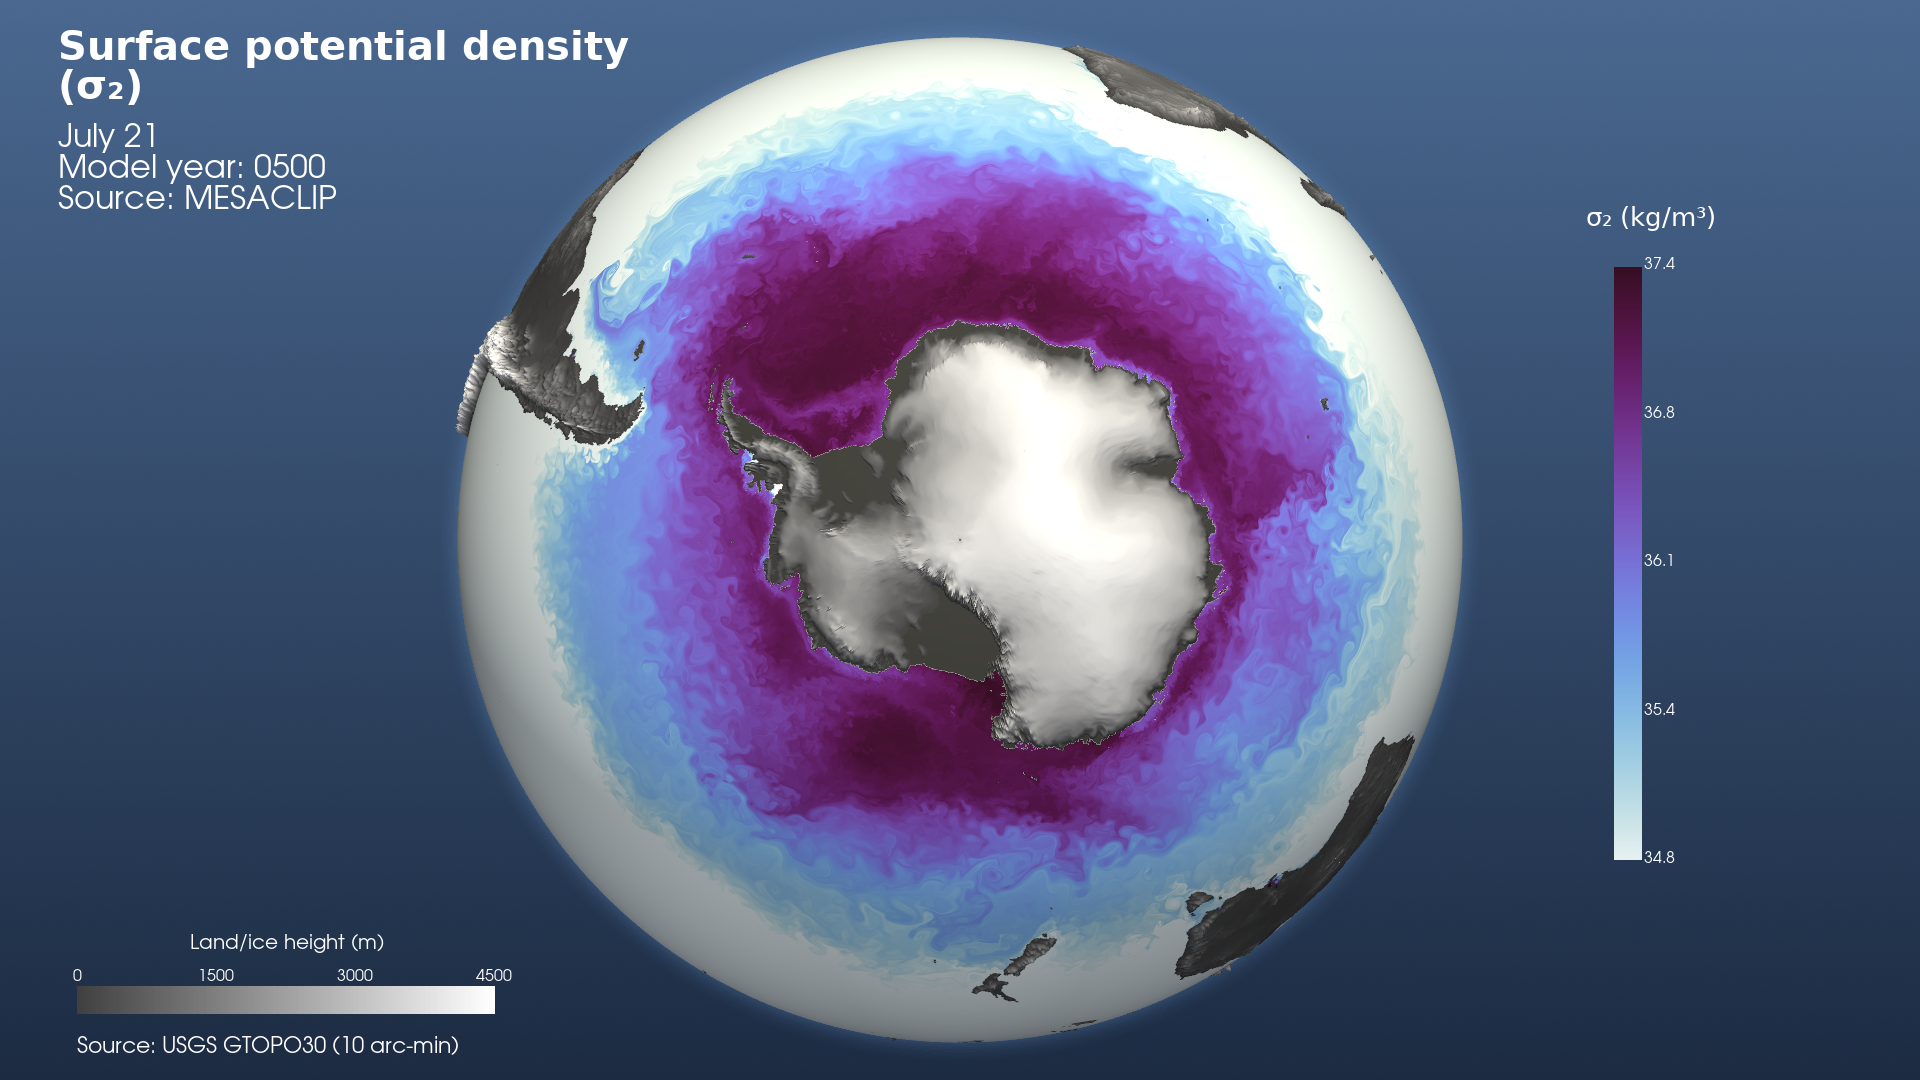

In [7]:
FRAME_FILE = "../plots/ssigma2_antarctica.png"

sigma2_day = sigma2.sel(time="0500-07-21").squeeze("time").load()

plotter = build_static_globe(LAND_MESH)
add_sigma2_layer(plotter, sigma2_day)
plotter.screenshot(FRAME_FILE)
plotter.close()

Image(FRAME_FILE)

## Region map
The single frame with the `REGIONS` outlined and labelled, saved before the movie.

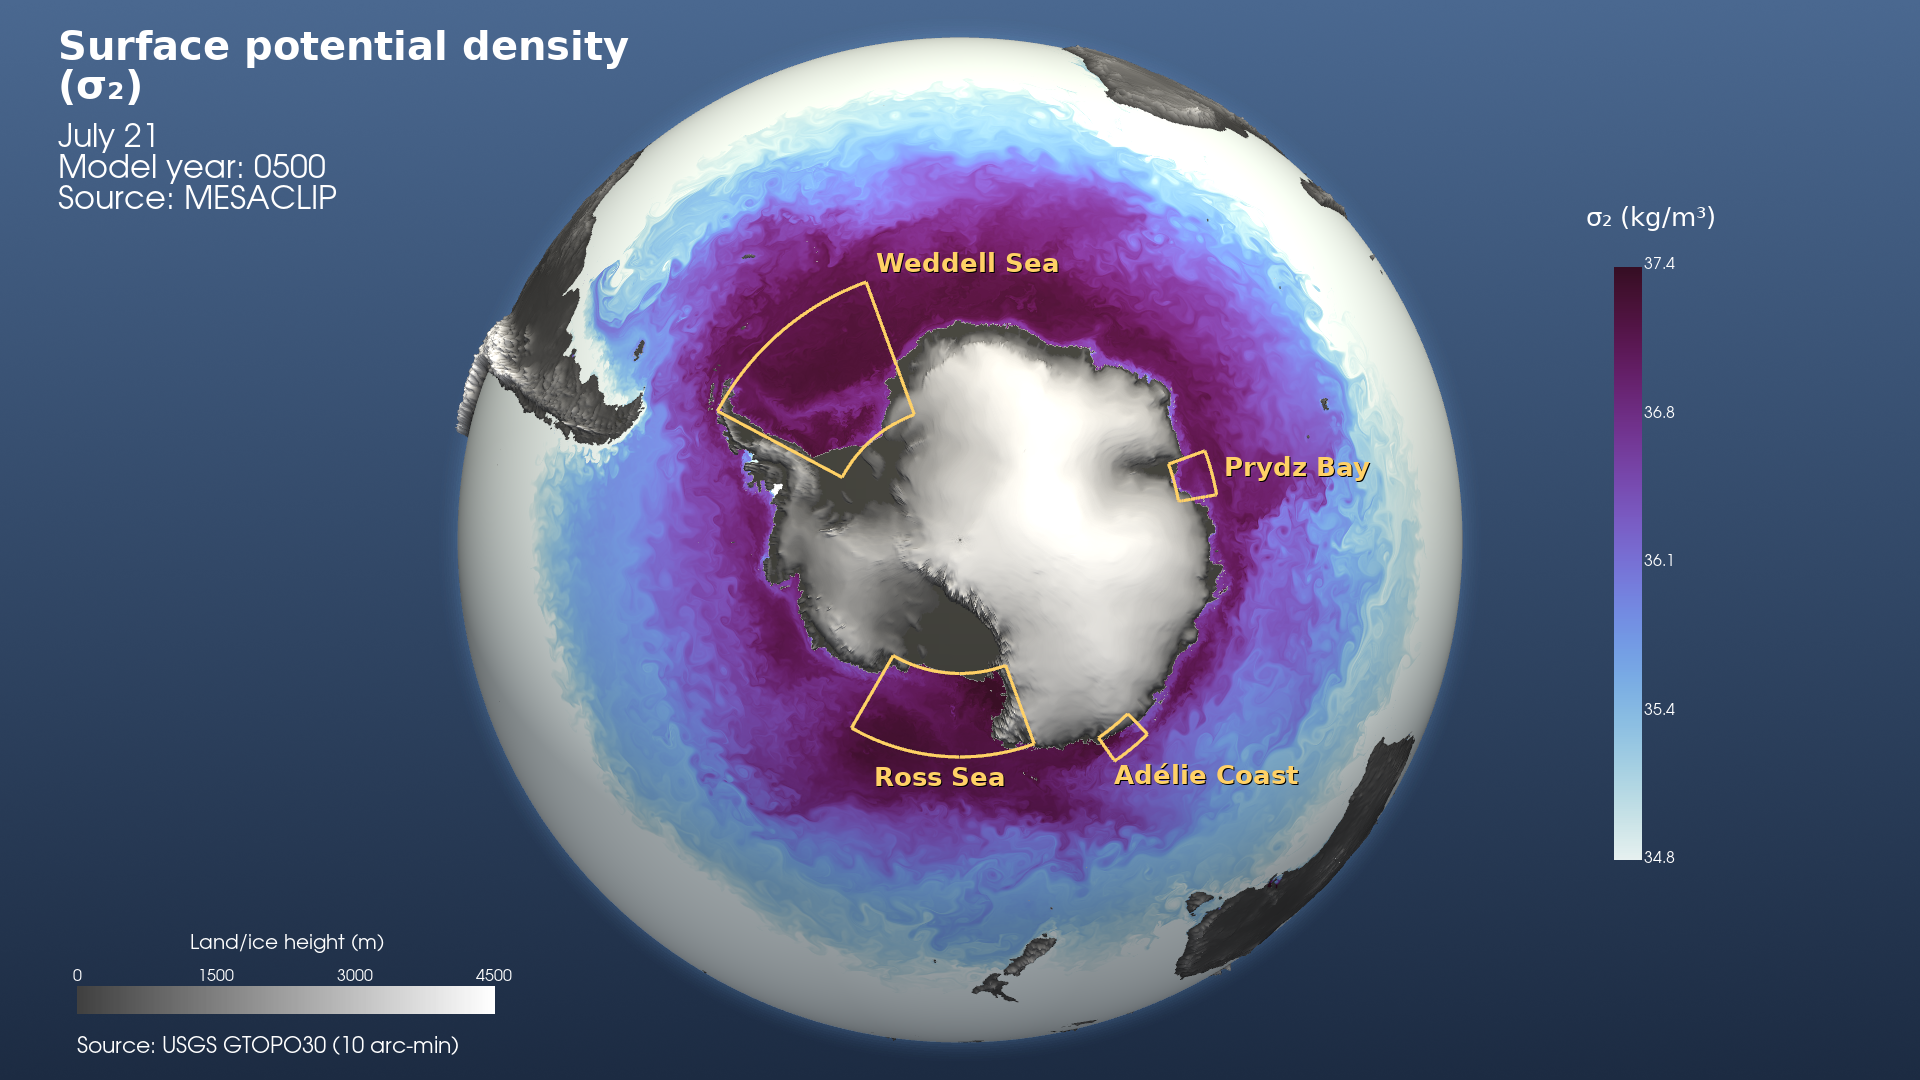

In [8]:
REGIONS_FILE = "../plots/ssigma2_antarctica_regions.png"

plotter = build_static_globe(LAND_MESH)
add_sigma2_layer(plotter, sigma2_day)
add_regions(plotter, REGIONS)
plotter.screenshot(REGIONS_FILE)
plotter.close()

Image(REGIONS_FILE)

## Movie
A pool of worker processes (one per core) renders the days, then ffmpeg joins the frames.
~4 s per frame per worker; ~1.5 GB memory per worker.

In [9]:
START_DATE          = "0500-01-01"
END_DATE            = "0501-12-31"   # inclusive
DAYS_PER_ANIMATION_SECOND = 7.5       # one frame per day, so this is also the frame rate
N_WORKERS           = len(os.sched_getaffinity(0))   # cores available to this session

FRAME_DIR = "../data/globe_frames"
MOVIE     = "../plots/ssigma2_antarctica.mp4"

sigma2_movie = sigma2.sel(time=slice(START_DATE, END_DATE))
n_frames = sigma2_movie.sizes["time"]
render_minutes = 4 * n_frames / N_WORKERS / 60   # ~4 s per frame per worker
print(f"{n_frames} frames = {n_frames / DAYS_PER_ANIMATION_SECOND:.0f} s of movie; {N_WORKERS} workers, ~{render_minutes:.0f} min to render")

730 frames = 97 s of movie; 8 workers, ~6 min to render


In [10]:
shutil.rmtree(FRAME_DIR, ignore_errors=True)   # start clean
os.makedirs(FRAME_DIR)

# Each worker builds its globe once, then takes the next day as soon as it is free
frames = list(enumerate(sigma2_movie.time.values))
payload = cloudpickle.dumps((build_static_globe, add_sigma2_layer, LAND_MESH, sigma2, FRAME_DIR))
spawn = multiprocessing.get_context("spawn")
with spawn.Pool(N_WORKERS, initializer=frame_worker.start, initargs=(payload,)) as pool:
    for _ in tqdm(pool.imap_unordered(frame_worker.render, frames), total=n_frames):
        pass

  0%|          | 0/730 [00:00<?, ?it/s]

In [11]:
subprocess.run([
    "ffmpeg", "-y", "-loglevel", "error",
    "-framerate", str(DAYS_PER_ANIMATION_SECOND),
    "-i", f"{FRAME_DIR}/frame_%04d.png",
    "-c:v", "libx264", "-crf", "18", "-pix_fmt", "yuv420p",   # H.264, plays everywhere
    MOVIE,
], check=True)
print("wrote", MOVIE)

wrote ../plots/ssigma2_antarctica.mp4
